In [3]:
import pandas as pd

df = pd.read_csv("../data/india_flight_delay_model_input.csv")
print("Shape (rows, columns):", df.shape)
print("\nColumns:\n", df.columns.tolist())
df.head()

Shape (rows, columns): (150000, 23)

Columns:
 ['Flight_Date', 'Airline', 'Flight_Number', 'Origin_Airport', 'Destination_Airport', 'Scheduled_Departure_Hour', 'Scheduled_Departure_Minute', 'Day_of_Week', 'Month', 'Is_Weekend', 'Peak_Hour', 'Weather', 'Temperature_C', 'Humidity_pct', 'Wind_Speed_kmh', 'Visibility_km', 'Rainfall_mm', 'Cloud_Cover_pct', 'Origin_Congestion_Index', 'Previous_Flight_Delay_Minutes', 'Turnaround_Risk_Index', 'Departure_Delay', 'Delay_Target']


,Flight_Date,Airline,Flight_Number,Origin_Airport,Destination_Airport,Scheduled_Departure_Hour,Scheduled_Departure_Minute,Day_of_Week,Month,Is_Weekend,...,Humidity_pct,Wind_Speed_kmh,Visibility_km,Rainfall_mm,Cloud_Cover_pct,Origin_Congestion_Index,Previous_Flight_Delay_Minutes,Turnaround_Risk_Index,Departure_Delay,Delay_Target
0,2025-12-04,IndiGo,IN8723,BOM,DEL,13,57,3,12,0,...,46.1,4.3,9.8,5.2,0.0,63.5,0,23.9,43,1
1,2024-01-15,IndiGo,IN558,CCU,HYD,19,14,0,1,0,...,70.5,8.9,11.7,0.4,39.8,95.3,1,31.5,49,1
2,2023-11-06,Vistara,VI4949,HYD,DEL,8,50,0,11,0,...,53.7,7.8,9.6,4.3,16.6,100.0,1,41.5,73,1
3,2025-08-08,SpiceJet,SP3196,BLR,DIB,11,56,4,8,0,...,42.0,1.5,12.6,4.6,23.6,51.1,1,28.2,40,1
4,2023-09-09,IndiGo,IN8458,BLR,JGA,22,59,5,9,1,...,58.5,1.3,11.3,3.5,36.2,67.0,0,27.9,0,0


In [4]:
df.info()
print("\nMissing values:\n", df.isnull().sum())
print("\nDuplicates:", df.duplicated().sum())


<class 'pandas.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 23 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Flight_Date                    150000 non-null  str    
 1   Airline                        150000 non-null  str    
 2   Flight_Number                  150000 non-null  str    
 3   Origin_Airport                 150000 non-null  str    
 4   Destination_Airport            150000 non-null  str    
 5   Scheduled_Departure_Hour       150000 non-null  int64  
 6   Scheduled_Departure_Minute     150000 non-null  int64  
 7   Day_of_Week                    150000 non-null  int64  
 8   Month                          150000 non-null  int64  
 9   Is_Weekend                     150000 non-null  int64  
 10  Peak_Hour                      150000 non-null  int64  
 11  Weather                        150000 non-null  str    
 12  Temperature_C                  150000 non

In [5]:
print("Last 5 columns:", df.columns[-5:].tolist())
print("Total missing values:", df.isnull().sum().sum())
print("\nDelay_Target %:\n", df["Delay_Target"].value_counts(normalize=True) * 100)


Last 5 columns: ['Origin_Congestion_Index', 'Previous_Flight_Delay_Minutes', 'Turnaround_Risk_Index', 'Departure_Delay', 'Delay_Target']
Total missing values: 0

Delay_Target %:
 Delay_Target
1    86.616667
0    13.383333
Name: proportion, dtype: float64


Matplotlib is building the font cache; this may take a moment.


   Departure_Delay  Delay_Target
0               43             1
1               49             1
2               73             1
3               40             1
4                0             0
5               54             1
6               46             1
7               46             1
8               43             1
9                0             0


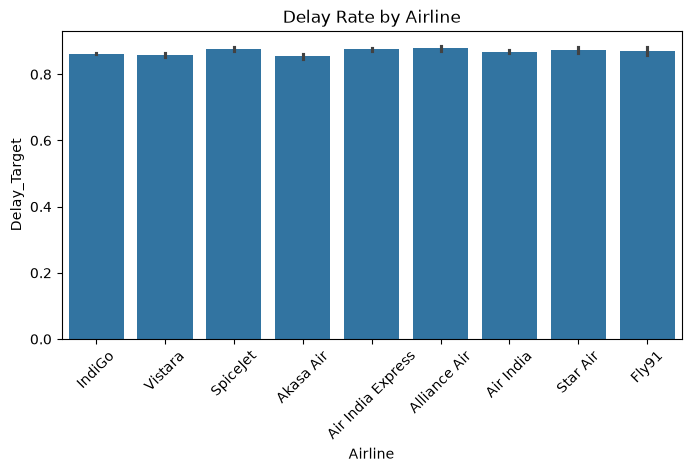

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

print(df[["Departure_Delay", "Delay_Target"]].head(10))

plt.figure(figsize=(8, 4))
sns.barplot(x="Airline", y="Delay_Target", data=df)
plt.title("Delay Rate by Airline")
plt.xticks(rotation=45)
plt.show()


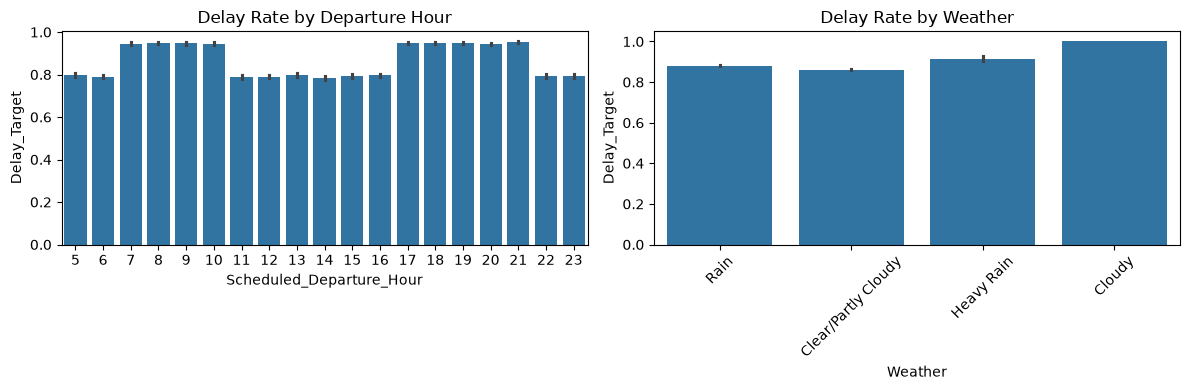

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.barplot(x="Scheduled_Departure_Hour", y="Delay_Target", data=df, ax=axes[0])
axes[0].set_title("Delay Rate by Departure Hour")

sns.barplot(x="Weather", y="Delay_Target", data=df, ax=axes[1])
axes[1].set_title("Delay Rate by Weather")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()
